# 03 · Final evaluation and thesis figures

This notebook is evaluation-only: it never trains or changes checkpoints. It discovers completed runs across all experiment names, makes the selected source of every result visible, and writes final tables and figures to Drive. CPU is sufficient.


## 1. Mount Drive and install reporting dependencies

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, math, shutil

ROOT = Path('/content/drive/MyDrive/SAR_Ship_Segmentation_Study')
assert ROOT.is_dir(), ROOT
print('Project:', ROOT)


Mounted at /content/drive
Project: /content/drive/MyDrive/SAR_Ship_Segmentation_Study


In [2]:
%pip install -q "numpy<2.3" pandas matplotlib seaborn pycocotools "clearml==2.1.12"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.6 MB/s eta 0:00:00


## 2. Discover completed runs

The newest completed non-smoke run is selected for each dataset/model. Review the displayed table before accepting the results. Use `RUN_OVERRIDES` only if a different completed experiment must be selected.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

MODELS = [
    'yolo26n_seg', 'yolo26s_seg', 'yolo26m_seg', 'rfdetr_seg',
    'samsar', 'ship_contour', 'swininsseg', 'solov2_gala'
]
DATASETS = ['ssdd', 'hrsid']

# Optional format: {('ssdd', 'model_name'): 'exact_experiment_folder'}
RUN_OVERRIDES = {}

def completed_candidates(dataset, model):
    base = ROOT / 'runs' / dataset / model
    if not base.is_dir():
        return []
    found = []
    for marker in base.glob('*/evaluation_complete.json'):
        if marker.parent.name.endswith('_smoke'):
            continue
        if (marker.parent / 'metrics' / 'test.json').is_file():
            found.append(marker.parent)
    return sorted(found, key=lambda p: (p/'evaluation_complete.json').stat().st_mtime,
                  reverse=True)

selected, audit = {}, []
for dataset in DATASETS:
    for model in MODELS:
        candidates = completed_candidates(dataset, model)
        override = RUN_OVERRIDES.get((dataset, model))
        chosen = ROOT/'runs'/dataset/model/override if override else (candidates[0] if candidates else None)
        if chosen is not None and chosen not in candidates:
            raise ValueError(f'Override is not a completed run: {chosen}')
        if chosen is not None:
            selected[(dataset, model)] = chosen
        audit.append({
            'dataset': dataset, 'model': model,
            'selected_experiment': chosen.name if chosen else None,
            'completed_candidates': ', '.join(p.name for p in candidates),
            'status': 'READY' if chosen else 'MISSING'
        })

selection = pd.DataFrame(audit)
display(selection)
missing = selection[selection.status == 'MISSING']
print('Missing model/dataset results:', len(missing))


,dataset,model,selected_experiment,completed_candidates,status
0,ssdd,yolo26n_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY
1,ssdd,yolo26s_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY
2,ssdd,yolo26m_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY
3,ssdd,rfdetr_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY
4,ssdd,samsar,study_v6_samsar_stable,study_v6_samsar_stable,READY
5,ssdd,ship_contour,study_v6_samsar_stable,study_v6_samsar_stable,READY
6,ssdd,swininsseg,study_v10_swininsseg_stable,study_v10_swininsseg_stable,READY
7,ssdd,solov2_gala,study_v11_solov2_gala,study_v11_solov2_gala,READY
8,hrsid,yolo26n_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY
9,hrsid,yolo26s_seg,study_v5_leakage_safe,study_v5_leakage_safe,READY


Missing model/dataset results: 0


## 3. Validate provenance and aggregate final metrics

In [4]:
REPORT = ROOT / 'reports' / 'final_evaluation'
FIGURES = REPORT / 'figures'
TABLES = REPORT / 'tables'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

rows = []
selection_payload = []
for (dataset, model), folder in selected.items():
    metrics = json.loads((folder/'metrics/test.json').read_text())
    if metrics.get('model') != model or metrics.get('training_dataset') != dataset:
        raise ValueError(f'Identity mismatch: {folder}')
    completion = json.loads((folder/'evaluation_complete.json').read_text())
    row = {
        'dataset': dataset, 'model': model, 'experiment': folder.name,
        'AP50_95': metrics.get('AP50_95'), 'AP50': metrics.get('AP50'),
        'AP75': metrics.get('AP75'), 'AP_small': metrics.get('AP_small'),
        'AP_medium': metrics.get('AP_medium'), 'AP_large': metrics.get('AP_large'),
        'Precision': metrics.get('Precision'), 'Recall': metrics.get('Recall'),
        'F1': metrics.get('F1'), 'FPS': metrics.get('FPS'),
        'params_M': metrics.get('params_M'), 'protocol': metrics.get('protocol'),
        'gpu': metrics.get('gpu'), 'threshold': metrics.get('conf_at_best_F1'),
        'checkpoint_sha256': metrics.get('checkpoint_sha256'),
        'split_fingerprint': metrics.get('split_fingerprint')
    }
    rows.append(row)
    selection_payload.append({'dataset':dataset, 'model':model, 'folder':str(folder),
                              'completion':completion})

results = pd.DataFrame(rows).sort_values(['dataset','AP50_95'], ascending=[True,False])
results.to_csv(TABLES/'segmentation_results.csv', index=False)
(REPORT/'selected_runs.json').write_text(json.dumps(selection_payload, indent=2))
selection.to_csv(TABLES/'run_selection_audit.csv', index=False)

display(results[['dataset','model','AP50_95','AP50','Precision','Recall','F1','FPS','protocol','experiment']])
print('Saved:', TABLES/'segmentation_results.csv')


,dataset,model,AP50_95,AP50,Precision,Recall,F1,FPS,protocol,experiment
10,hrsid,yolo26m_seg,38.222124,76.657082,79.390325,73.004266,76.063492,47.089661,end2end,study_v5_leakage_safe
12,hrsid,samsar,36.611371,78.538587,83.974359,79.829372,81.849422,34.463209,ground_truth_box_prompted,study_v6_samsar_stable
11,hrsid,rfdetr_seg,33.936860,69.833835,82.448037,65.265082,72.857143,18.616306,end2end,study_v5_leakage_safe
9,hrsid,yolo26s_seg,33.683296,71.005124,88.165138,58.561853,70.377151,46.996476,end2end,study_v5_leakage_safe
8,hrsid,yolo26n_seg,29.207362,63.276018,67.593790,63.680683,65.578914,44.240282,end2end,study_v5_leakage_safe
13,hrsid,ship_contour,19.404816,47.000087,67.175573,42.900670,52.361473,8.722212,end2end,study_v6_samsar_stable
14,hrsid,swininsseg,15.206047,38.938828,87.690180,38.634979,53.637902,13.288664,end2end,study_v10_swininsseg_stable
15,hrsid,solov2_gala,0.000000,0.000000,0.000000,0.000000,0.000000,11.989828,end2end,study_v11_solov2_gala
4,ssdd,samsar,67.562236,98.951873,99.816514,99.633700,99.725023,52.335166,ground_truth_box_prompted,study_v6_samsar_stable
3,ssdd,rfdetr_seg,62.283893,95.728425,97.509579,93.223443,95.318352,67.114919,end2end,study_v5_leakage_safe


Saved: /content/drive/MyDrive/SAR_Ship_Segmentation_Study/reports/final_evaluation/tables/segmentation_results.csv


## 4. LS-SSD cross-dataset generalization

In [5]:
generalization = []
for (dataset, model), folder in selected.items():
    path = folder/'metrics/ls_ssdd.json'
    if dataset != 'ssdd' or not path.is_file():
        continue
    values = json.loads(path.read_text())
    generalization.append({
        'model':model, 'trained_on':'ssdd',
        'box_Precision':values.get('box_Precision'),
        'box_Recall':values.get('box_Recall'), 'box_F1':values.get('box_F1'),
        'FPS':values.get('FPS'), 'experiment':folder.name
    })

generalization_results = pd.DataFrame(generalization)
generalization_results.to_csv(TABLES/'ls_ssdd_generalization.csv', index=False)
display(generalization_results.sort_values('box_F1', ascending=False) if len(generalization_results) else generalization_results)


,model,trained_on,box_Precision,box_Recall,box_F1,FPS,experiment
4,ship_contour,ssdd,72.727273,19.619865,30.902945,9.949303,study_v6_samsar_stable
1,yolo26s_seg,ssdd,46.029610,20.968731,28.812131,39.644259,study_v5_leakage_safe
2,yolo26m_seg,ssdd,36.022514,23.543838,28.476085,68.661519,study_v5_leakage_safe
3,rfdetr_seg,ssdd,45.466847,20.600858,28.354430,28.959689,study_v5_leakage_safe
0,yolo26n_seg,ssdd,37.960954,21.459227,27.418723,58.020683,study_v5_leakage_safe
5,swininsseg,ssdd,45.188285,6.621704,11.550802,16.919090,study_v10_swininsseg_stable
6,solov2_gala,ssdd,0.000000,0.000000,0.000000,12.755958,study_v11_solov2_gala


## 5. Thesis-ready comparison figures

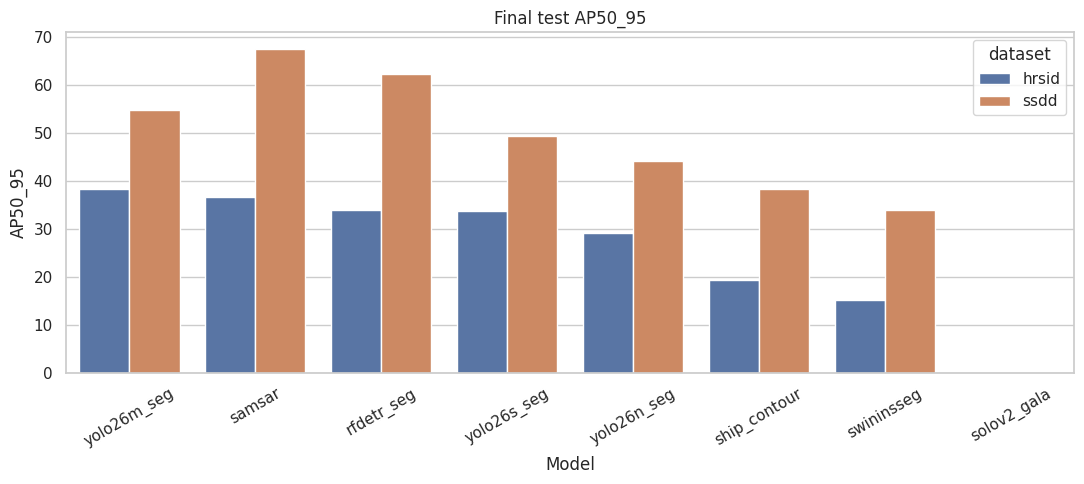

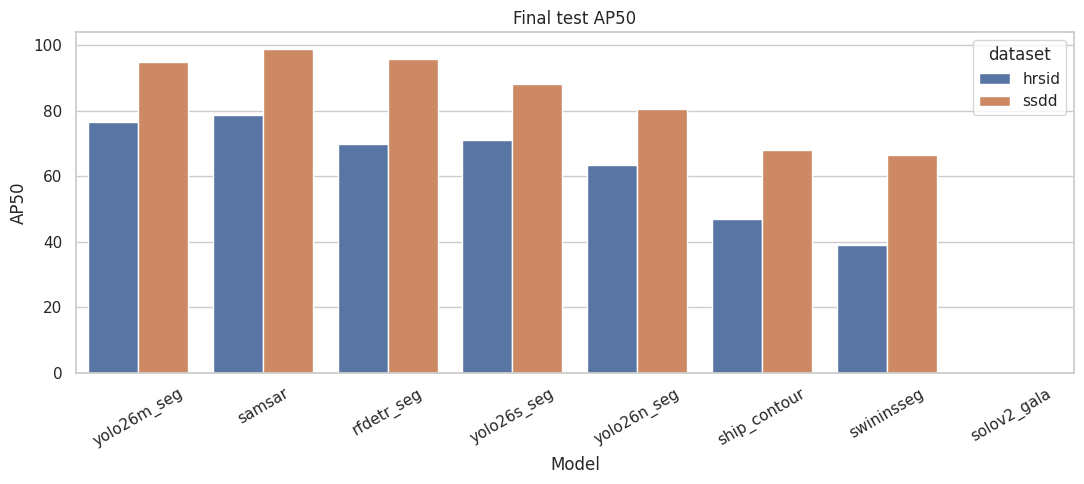

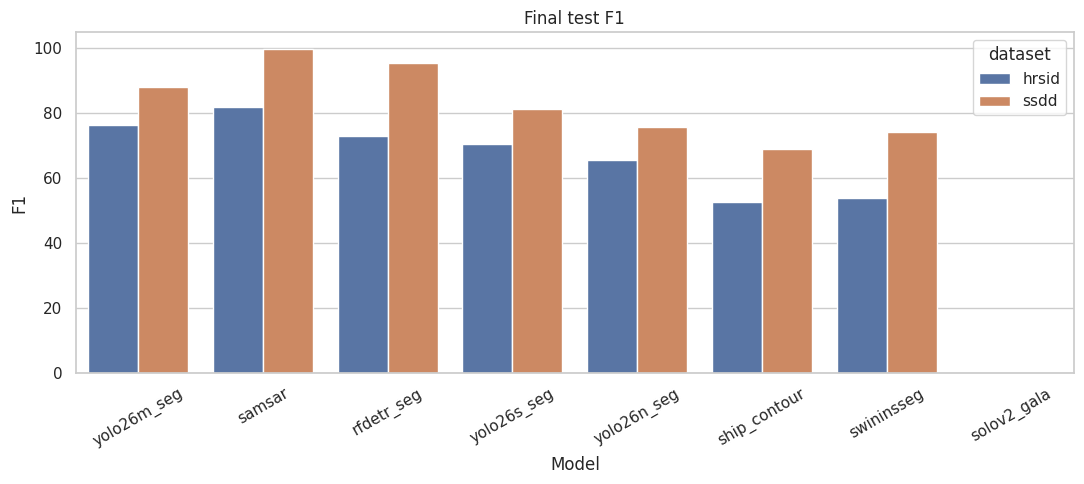

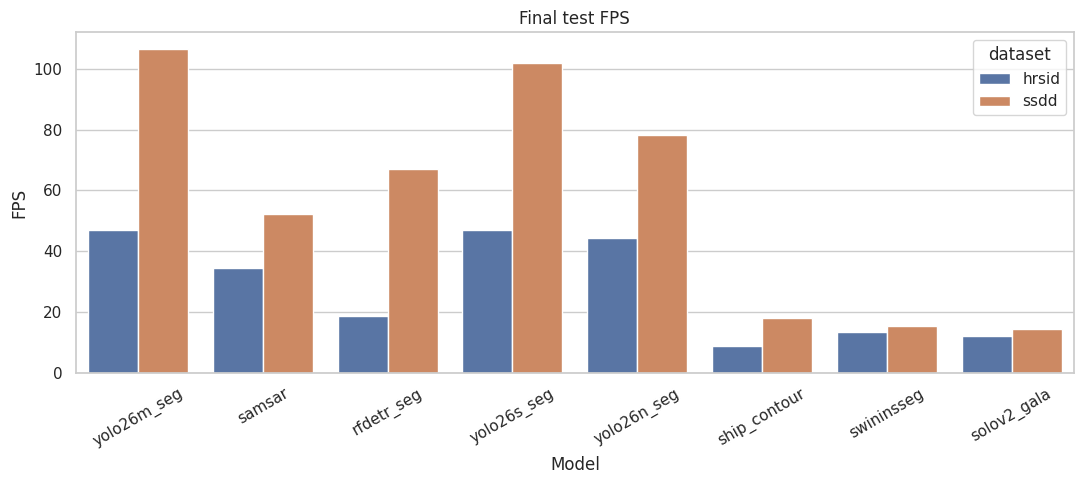

Figures saved: /content/drive/MyDrive/SAR_Ship_Segmentation_Study/reports/final_evaluation/figures


In [6]:
sns.set_theme(style='whitegrid', context='notebook')
for metric in ['AP50_95','AP50','F1','FPS']:
    available = results.dropna(subset=[metric])
    if available.empty:
        continue
    fig, ax = plt.subplots(figsize=(11,5))
    sns.barplot(data=available, x='model', y=metric, hue='dataset', ax=ax)
    ax.set_title(f'Final test {metric}')
    ax.set_xlabel('Model'); ax.tick_params(axis='x', rotation=30)
    fig.tight_layout()
    path = FIGURES/f'comparison_{metric}.png'
    fig.savefig(path, dpi=220, bbox_inches='tight')
    plt.show(); plt.close(fig)
print('Figures saved:', FIGURES)


## 6. Training and validation curves

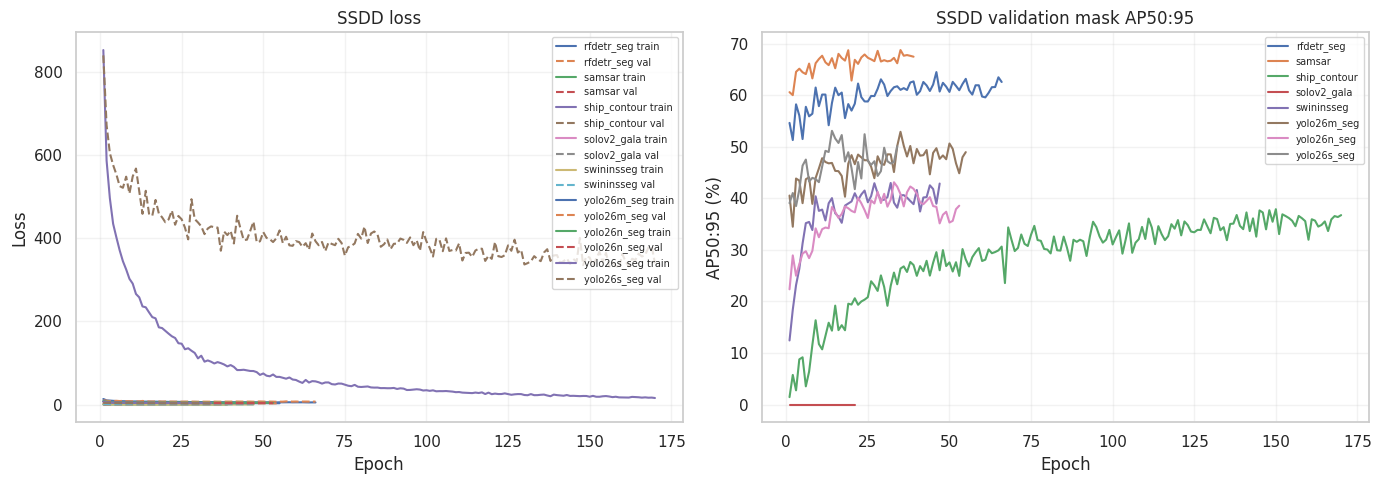

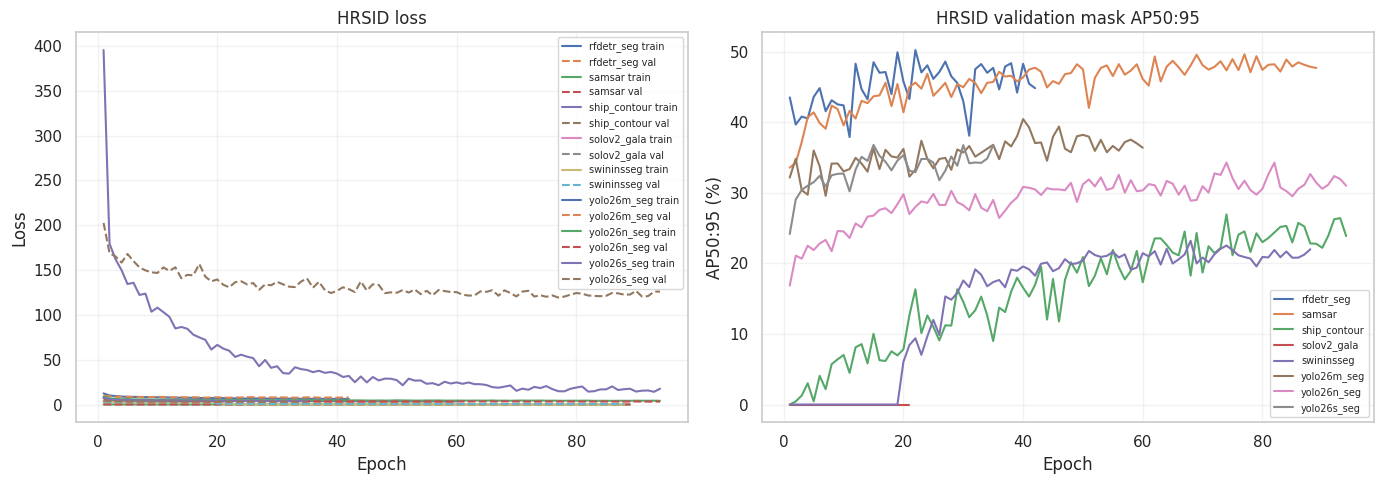

In [7]:
curve_rows=[]
for (dataset, model), folder in selected.items():
    history_path=folder/'history.json'
    if not history_path.is_file():
        continue
    for record in json.loads(history_path.read_text()):
        curve_rows.append({'dataset':dataset,'model':model,**record})

history=pd.DataFrame(curve_rows)
if history.empty:
    print('No histories found')
else:
    for dataset in DATASETS:
        part=history[history.dataset==dataset]
        if part.empty: continue
        fig,axes=plt.subplots(1,2,figsize=(14,5))
        for model,group in part.groupby('model'):
            group=group.sort_values('epoch')
            axes[0].plot(group.epoch,group.train_loss,label=f'{model} train')
            axes[0].plot(group.epoch,group.val_loss,linestyle='--',label=f'{model} val')
            axes[1].plot(group.epoch,group.val_mask_AP50_95,label=model)
        axes[0].set(title=f'{dataset.upper()} loss',xlabel='Epoch',ylabel='Loss')
        axes[1].set(title=f'{dataset.upper()} validation mask AP50:95',xlabel='Epoch',ylabel='AP50:95 (%)')
        for ax in axes: ax.legend(fontsize=7); ax.grid(alpha=.25)
        fig.tight_layout(); fig.savefig(FIGURES/f'{dataset}_learning_curves.png',dpi=220)
        plt.show(); plt.close(fig)


## 7. Instance-level confusion matrices

Rows are actual instances and columns are predicted instances. `Background→Background` is undefined for object detection and is shown as zero. Matching uses mask IoU ≥ 0.50 and each run's validation-selected confidence threshold.

In [9]:
from pycocotools import mask as mask_utils
from collections import defaultdict

def normalise_rle(rle):
    value = dict(rle)

    if isinstance(value.get("counts"), str):
        value["counts"] = value["counts"].encode("ascii")

    return value


def instance_counts(
    gt_path,
    prediction_path,
    threshold,
    iou_threshold=0.5,
):
    gt = json.loads(Path(gt_path).read_text())
    predictions = json.loads(Path(prediction_path).read_text())

    truth = defaultdict(list)
    pred = defaultdict(list)

    shapes = {
        int(image["id"]): (
            int(image["height"]),
            int(image["width"]),
        )
        for image in gt["images"]
    }

    for annotation in gt["annotations"]:
        segmentation = annotation["segmentation"]
        image_id = int(annotation["image_id"])

        if isinstance(segmentation, list):
            height, width = shapes[image_id]
            segmentation = mask_utils.merge(
                mask_utils.frPyObjects(
                    segmentation,
                    height,
                    width,
                )
            )

        truth[image_id].append(
            normalise_rle(segmentation)
        )

    for item in predictions:
        if float(item.get("score", 1)) >= threshold:
            pred[int(item["image_id"])].append(
                normalise_rle(item["segmentation"])
            )

    tp = 0
    fp = 0
    fn = 0

    for image_id in set(truth) | set(pred):
        actual = truth[image_id]
        predicted = pred[image_id]

        if actual and predicted:
            ious = mask_utils.iou(
                predicted,
                actual,
                [0] * len(actual),
            )

            candidates = sorted(
                (
                    -float(ious[pred_index, actual_index]),
                    pred_index,
                    actual_index,
                )
                for pred_index in range(len(predicted))
                for actual_index in range(len(actual))
                if ious[pred_index, actual_index] >= iou_threshold
            )

            matched_predictions = set()
            matched_actual = set()

            for _, pred_index, actual_index in candidates:
                if (
                    pred_index not in matched_predictions
                    and actual_index not in matched_actual
                ):
                    matched_predictions.add(pred_index)
                    matched_actual.add(actual_index)
                    tp += 1

            fp += len(predicted) - len(matched_predictions)
            fn += len(actual) - len(matched_actual)

        else:
            fp += len(predicted)
            fn += len(actual)

    return tp, fp, fn


confusion_rows = []

for (dataset, model), folder in selected.items():
    threshold_path = folder / "threshold.json"
    prediction_path = folder / "predictions" / "test.json"

    # Permanent ground truth stored in Drive
    ground_truth_path = (
        ROOT
        / "splits"
        / folder.name
        / dataset
        / "test.json"
    )

    if not threshold_path.is_file():
        print("Missing threshold:", threshold_path)
        continue

    if not prediction_path.is_file():
        print("Missing predictions:", prediction_path)
        continue

    if not ground_truth_path.is_file():
        print("Missing ground truth:", ground_truth_path)
        continue

    threshold = json.loads(
        threshold_path.read_text()
    )["value"]

    tp, fp, fn = instance_counts(
        ground_truth_path,
        prediction_path,
        threshold,
    )

    confusion_rows.append(
        {
            "dataset": dataset,
            "model": model,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "threshold": threshold,
        }
    )

    matrix = np.array([
        [tp, fn],
        [fp, 0],
    ])

    fig, ax = plt.subplots(figsize=(5, 4))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Ship", "Background"],
        yticklabels=["Ship", "Background"],
        ax=ax,
    )

    ax.set(
        xlabel="Predicted",
        ylabel="Actual",
        title=f"{dataset.upper()} · {model} · IoU ≥ 0.50",
    )

    fig.tight_layout()

    output_path = (
        FIGURES
        / f"confusion_{dataset}_{model}.png"
    )

    fig.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
    )

    plt.close(fig)


confusion = pd.DataFrame(confusion_rows)

confusion.to_csv(
    TABLES / "instance_confusion_counts.csv",
    index=False,
)

display(confusion)

,dataset,model,TP,FP,FN,threshold
0,ssdd,yolo26n_seg,401,116,145,0.288802
1,ssdd,yolo26s_seg,403,45,143,0.340965
2,ssdd,yolo26m_seg,487,74,59,0.244844
3,ssdd,rfdetr_seg,509,13,37,0.454761
4,ssdd,samsar,544,1,2,0.699098
5,ssdd,ship_contour,346,112,200,0.415167
6,ssdd,swininsseg,335,25,211,0.775250
7,ssdd,solov2_gala,0,0,546,1.000000
8,hrsid,yolo26n_seg,1045,501,596,0.271685
9,hrsid,yolo26s_seg,961,129,680,0.319493


In [10]:
# QUALITATIVE SEGMENTATION VISUALISATIONS
# Red = predicted segmentation, Green = ground-truth outline

import json
import zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageDraw
from pycocotools import mask as mask_utils

EXAMPLES_PER_MODEL = 1        # Change to 2 if you want two images per model
PREDICTION_COLOUR = (255, 0, 0)
GROUND_TRUTH_COLOUR = (0, 255, 0)
MASK_ALPHA = 0.40

QUALITATIVE_DIR = FIGURES / "qualitative"
QUALITATIVE_DIR.mkdir(parents=True, exist_ok=True)


def stable_image_id(value):
    """Generate the same image ID used by the benchmark."""
    return zlib.crc32(str(value).encode("utf-8")) & 0x7FFFFFFF


def load_json(path):
    path = Path(path)
    if not path.is_file():
        return None
    return json.loads(path.read_text())


def get_record_path(record):
    """Find the image path regardless of the manifest field name."""
    for key in ("image_path", "path", "file_name", "image", "source_image"):
        value = record.get(key)
        if value:
            return Path(value)
    return None


def get_record_id(record):
    """Recover the prediction image ID for a manifest record."""
    if record.get("source_image_id") is not None:
        return int(record["source_image_id"])

    if record.get("image_id") is not None:
        return int(record["image_id"])

    image_path = get_record_path(record)

    candidates = [
        record.get("source_key"),
        record.get("relative_path"),
        record.get("file_name"),
        str(image_path) if image_path else None,
    ]

    for value in candidates:
        if value:
            return stable_image_id(value)

    return None


def decode_mask(segmentation, height, width):
    """Convert polygon or RLE segmentation into a binary mask."""
    if segmentation is None:
        return None

    try:
        if isinstance(segmentation, list):
            rles = mask_utils.frPyObjects(segmentation, height, width)
            rle = mask_utils.merge(rles)
        else:
            rle = dict(segmentation)
            if isinstance(rle.get("counts"), str):
                rle["counts"] = rle["counts"].encode("ascii")

        mask = mask_utils.decode(rle)

        if mask.ndim == 3:
            mask = np.any(mask, axis=2)

        return mask.astype(bool)

    except Exception as error:
        print("Could not decode one mask:", error)
        return None


def overlay_predictions(image, predictions):
    """Add transparent red predicted masks."""
    image = image.convert("RGB")
    array = np.asarray(image).copy()

    overlay = np.zeros_like(array)
    combined_mask = np.zeros(array.shape[:2], dtype=bool)

    for prediction in predictions:
        mask = decode_mask(
            prediction.get("segmentation"),
            array.shape[0],
            array.shape[1],
        )

        if mask is not None and mask.shape == combined_mask.shape:
            combined_mask |= mask

    overlay[combined_mask] = PREDICTION_COLOUR

    result = array.astype(np.float32)
    result[combined_mask] = (
        (1 - MASK_ALPHA) * result[combined_mask]
        + MASK_ALPHA * overlay[combined_mask]
    )

    return Image.fromarray(np.clip(result, 0, 255).astype(np.uint8))


def draw_ground_truth(image, record):
    """Draw available ground-truth polygons in green."""
    draw = ImageDraw.Draw(image)

    annotations = (
        record.get("annotations")
        or record.get("instances")
        or record.get("objects")
        or []
    )

    for annotation in annotations:
        segmentation = annotation.get("segmentation", [])

        if not isinstance(segmentation, list):
            continue

        for polygon in segmentation:
            if not polygon or len(polygon) < 6:
                continue

            points = list(zip(polygon[0::2], polygon[1::2]))
            draw.line(points + [points[0]], fill=GROUND_TRUTH_COLOUR, width=2)

    return image


def load_dataset_records(dataset, run_folder):
    """Load persistent test/generalisation records from Drive."""
    if dataset == "ls_ssdd":
        manifest_path = (
            ROOT / "splits" / run_folder.name
            / "ls_ssdd" / "manifest.json"
        )
    else:
        manifest_path = (
            ROOT / "splits" / run_folder.name
            / dataset / "manifest.json"
        )

    manifest = load_json(manifest_path)

    if manifest is None:
        return []

    records = manifest.get("records", [])

    if isinstance(records, dict):
        if dataset == "ls_ssdd":
            records = (
                records.get("test")
                or records.get("generalization")
                or records.get("records")
                or []
            )
        else:
            records = records.get("test", [])

    return records


def load_predictions(dataset, run_folder):
    if dataset == "ls_ssdd":
        prediction_path = run_folder / "predictions" / "ls_ssdd.json"
    else:
        prediction_path = run_folder / "predictions" / "test.json"

    predictions = load_json(prediction_path)
    return predictions or [], prediction_path


def visualise_model(dataset, model, run_folder, number=1):
    records = load_dataset_records(dataset, run_folder)
    predictions, prediction_path = load_predictions(dataset, run_folder)

    if not records:
        print(f"Skipped {dataset}/{model}: manifest not found")
        return []

    if not prediction_path.is_file():
        print(f"Skipped {dataset}/{model}: predictions not found")
        return []

    threshold_file = run_folder / "threshold.json"
    threshold_data = load_json(threshold_file) or {}
    threshold = float(threshold_data.get("value", 0.0))

    predictions = [
        prediction
        for prediction in predictions
        if float(prediction.get("score", 1.0)) >= threshold
    ]

    predictions_by_image = {}

    for prediction in predictions:
        image_id = int(prediction["image_id"])
        predictions_by_image.setdefault(image_id, []).append(prediction)

    # Prefer examples containing at least one predicted ship
    ranked_records = sorted(
        records,
        key=lambda record: len(
            predictions_by_image.get(get_record_id(record), [])
        ),
        reverse=True,
    )

    outputs = []

    for example_number, record in enumerate(ranked_records[:number], start=1):
        image_path = get_record_path(record)
        image_id = get_record_id(record)

        if image_path is None or not image_path.is_file():
            print(f"Missing image for {dataset}/{model}:", image_path)
            continue

        image = Image.open(image_path).convert("RGB")
        model_predictions = predictions_by_image.get(image_id, [])

        visualisation = overlay_predictions(image, model_predictions)
        visualisation = draw_ground_truth(visualisation, record)

        output_path = (
            QUALITATIVE_DIR
            / f"{dataset}_{model}_example_{example_number}.png"
        )

        visualisation.save(output_path)

        outputs.append({
            "dataset": dataset,
            "model": model,
            "image_id": image_id,
            "detections": len(model_predictions),
            "threshold": threshold,
            "output": str(output_path),
        })

        plt.figure(figsize=(8, 8))
        plt.imshow(visualisation)
        plt.title(
            f"{dataset.upper()} — {model}\n"
            f"Predicted ships: {len(model_predictions)}"
        )
        plt.axis("off")
        plt.tight_layout()
        plt.show()

    return outputs


qualitative_rows = []

# SSDD and HRSID test-set visualisations
for (dataset, model), run_folder in sorted(selected.items()):
    if dataset not in ("ssdd", "hrsid"):
        continue

    qualitative_rows.extend(
        visualise_model(
            dataset,
            model,
            run_folder,
            number=EXAMPLES_PER_MODEL,
        )
    )

# LS-SSD generalisation uses each model trained on SSDD
ssdd_models = {
    model: run_folder
    for (dataset, model), run_folder in selected.items()
    if dataset == "ssdd"
}

for model, run_folder in sorted(ssdd_models.items()):
    qualitative_rows.extend(
        visualise_model(
            "ls_ssdd",
            model,
            run_folder,
            number=EXAMPLES_PER_MODEL,
        )
    )

qualitative_table = pd.DataFrame(qualitative_rows)
display(qualitative_table)

qualitative_table.to_csv(
    TABLES / "qualitative_visualisations.csv",
    index=False,
)

print("Visualisations saved in:", QUALITATIVE_DIR)

Output hidden; open in https://colab.research.google.com to view.

## 8. Final completeness check

In [ ]:
expected={(d,m) for d in DATASETS for m in MODELS}
ready=set(selected)
print('Completed:',len(ready),'/',len(expected))
print('Missing:',sorted(expected-ready) or 'None')
print('Final report folder:',REPORT)


## 9. Optional: upload the final report to ClearML

Run this only after reviewing the selection and tables above. Store `CLEARML_ACCESS_KEY` and `CLEARML_SECRET_KEY` in Colab Secrets.

In [ ]:
UPLOAD_TO_CLEARML = False  # Change to True after reviewing the results.

if UPLOAD_TO_CLEARML:
    from google.colab import userdata
    import os
    os.environ['CLEARML_API_ACCESS_KEY']=userdata.get('CLEARML_ACCESS_KEY')
    os.environ['CLEARML_API_SECRET_KEY']=userdata.get('CLEARML_SECRET_KEY')
    os.environ['CLEARML_API_HOST']='https://api.clear.ml'
    os.environ['CLEARML_WEB_HOST']='https://app.clear.ml'
    os.environ['CLEARML_FILES_HOST']='https://files.clear.ml'
    from clearml import Task
    task=Task.init(project_name='SAR Ship Segmentation Study',
                   task_name='Final evaluation report',reuse_last_task_id=False,
                   auto_connect_frameworks=False)
    task.upload_artifact('selected_runs',artifact_object=str(REPORT/'selected_runs.json'))
    for path in sorted(TABLES.glob('*')): task.upload_artifact(path.name,artifact_object=str(path))
    for path in sorted(FIGURES.glob('*.png')): task.upload_artifact(path.name,artifact_object=str(path))
    task.flush(wait_for_uploads=True); task.close()
    print('Final report uploaded to ClearML')
else:
    print('ClearML upload skipped; all outputs are already saved in Drive.')
